# 09 — Deep Learning (RNN & LSTM) for Time-Series Analysis & 5% Threshold Classification
**AgriProcure Project** — Unit 3: Advanced Deep Learning Extension  
**Models Evaluated:** SimpleRNN, LSTM, Tuned XGBoost, Random Forest, Logistic Regression, Naive Baseline  
**Threshold Specification:** $\pm 5.0\%$ Price Movement Band (Rise, Fall, Flat) & Binary Spike Prediction

---

## Executive Summary & Motivation
While tree-based models (XGBoost, CatBoost) operate on tabular feature matrices with static lag columns, **Recurrent Neural Networks (RNN)** and **Long Short-Term Memory Networks (LSTM)** process **temporal sequence windows** ($X_{t-3}, X_{t-2}, X_{t-1}, X_t$), enabling the hidden state to capture multi-week memory, momentum decay, and non-linear meteorological shocks.

In this notebook, we extend our analytics framework:
1. **±5% Threshold Target Definition:**
   - **3-Class Direction:**
     - **Rise (> +5%):** Procurement risk window requiring advance buffer stocking.
     - **Fall (< -5%):** Potential glut window for delaying spot purchases.
     - **Flat ([-5%, +5%]):** Stable trading band for Just-in-Time procurement.
   - **Binary Spike Prediction:** Price Increase $>+5\%$ vs Rest (Flat or Fall).
2. **Deep Sequence Modeling with PyTorch:**
   - **SimpleRNN:** 2-layer recurrent architecture with dropout regularization.
   - **LSTM:** 2-layer gating architecture capable of learning long-term dependencies without vanishing gradients.
3. **Dual-Capability Evaluation:**
   - **Classification:** Predicting next-week categorical movement (Accuracy, Macro-F1, Precision, Recall, ROC-AUC).
   - **Time-Series Regression:** Continuous price forecasting ($y_{t+1}$) with RMSE, MAE, and MAPE.
4. **Comprehensive Model Benchmarking:** Benchmarking Deep Learning against Tuned XGBoost, Random Forest, Logistic Regression, and the Naive Persistence baseline.

In [1]:
import os
import sys
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, roc_auc_score, mean_squared_error, mean_absolute_error
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print("PyTorch and Scikit-Learn libraries loaded successfully.")
print(f"PyTorch version: {torch.__version__} | Device: {'cuda' if torch.cuda.is_available() else 'cpu'}")

PyTorch and Scikit-Learn libraries loaded successfully.
PyTorch version: 2.6.0+cpu | Device: cpu


## 1. ±5% Threshold Target Discretization & Data Inspection
We load the panel feature matrix and define the $\pm 5\%$ threshold.

In [2]:
sys.path.append("../scripts")
import train_rnn_lstm_classification as dl_pipeline

df, train_df, test_df, feature_cols, X_train, X_test, y_train_3c, y_test_3c, y_train_bin, y_test_bin, scaler = dl_pipeline.load_and_prepare_5pct_data()

print(f"Total features: {len(feature_cols)}")
print(f"Training observations: {len(train_df)} | Test observations: {len(test_df)}")

Loaded dataset: 9030 rows. Feature dimension: 37.
Class distribution on full panel with 5% threshold:
  - Fall (<-5%)       :  1704 (18.87%)
  - Rise (>+5%)       :  1986 (21.99%)
  - Flat ([-5%, +5%]) :  5340 (59.14%)
Binary Increase (>+5% vs Rest): 1986 (21.99%)
Total features: 37
Training observations: 6720 | Test observations: 2310


## 2. Sequence Window Generator for Deep Learning
For each mandi-crop pair, we construct rolling temporal sequence windows of length $L = 4$ weeks.
Input tensor shape: `(batch_size, sequence_length=4, num_features=37)`.

In [3]:
train_seq_ds = dl_pipeline.MandiSequenceDataset(train_df, feature_cols, scaler, seq_len=4, target_type="3class")
test_seq_ds = dl_pipeline.MandiSequenceDataset(test_df, feature_cols, scaler, seq_len=4, target_type="3class")

print(f"Constructed {len(train_seq_ds)} training sequences and {len(test_seq_ds)} test sequences.")
sample_x, sample_y = train_seq_ds[0]
print(f"Sample sequence shape: {sample_x.shape} -> Target label: {sample_y.item()}")

Constructed 6090 training sequences and 1680 test sequences.
Sample sequence shape: torch.Size([4, 37]) -> Target label: 2


## 3. PyTorch Deep SimpleRNN & LSTM Architectures
We define:
- **SimpleRNN:** Updates hidden state: $h_t = \tanh(W_{ih} x_t + W_{hh} h_{t-1} + b)$
- **LSTM:** Mitigates vanishing gradients via Input ($i_t$), Forget ($f_t$), and Output ($o_t$) gates:
  $$f_t = \sigma(W_f x_t + U_f h_{t-1} + b_f)$$
  $$i_t = \sigma(W_i x_t + U_i h_{t-1} + b_i)$$
  $$c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t$$
  $$o_t = \sigma(W_o x_t + U_o h_{t-1} + b_o)$$
  $$h_t = o_t \odot \tanh(c_t)$$

In [4]:
rnn_model = dl_pipeline.AgriRNN(input_size=len(feature_cols), hidden_size=64, num_layers=2, num_classes=3, dropout=0.2)
lstm_model = dl_pipeline.AgriLSTM(input_size=len(feature_cols), hidden_size=64, num_layers=2, num_classes=3, dropout=0.2)

print("--- SimpleRNN Architecture ---")
print(rnn_model)
print("\n--- LSTM Architecture ---")
print(lstm_model)

--- SimpleRNN Architecture ---
AgriRNN(
  (rnn): RNN(37, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
  (fc2): Linear(in_features=32, out_features=3, bias=True)
)

--- LSTM Architecture ---
AgriLSTM(
  (lstm): LSTM(37, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
  (fc2): Linear(in_features=32, out_features=3, bias=True)
)


## 4. Benchmark Execution: 3-Class & Binary Classification (5% Band)
We load the pre-computed metrics and confusion matrices across all evaluated models.

In [5]:
metrics_3c_path = "../reports/dl_and_ml_classification_metrics_5pct.csv"
metrics_bin_path = "../reports/binary_prediction_metrics_5pct.csv"

df_3c = pd.read_csv(metrics_3c_path)
df_bin = pd.read_csv(metrics_bin_path)

print("--- 3-Class Classification Benchmark (+-5% Threshold) ---")
display(df_3c)

print("\n--- Binary Spike Prediction Benchmark (Increase > +5% vs Rest) ---")
display(df_bin)

--- 3-Class Classification Benchmark (+-5% Threshold) ---


,Model,Accuracy,Macro_F1,Weighted_F1,Precision_Fall,Precision_Rise,Precision_Flat,Recall_Fall,Recall_Rise,Recall_Flat,ROC_AUC_OvR
0,Naive Persistence Baseline,0.4325,0.2421,0.4340,0.0035,0.0628,0.6616,0.0034,0.0653,0.6558,0.5000
1,Logistic Regression,0.5675,0.5274,0.5783,0.3297,0.4793,0.7315,0.5171,0.6715,0.5385,0.7427
2,Random Forest,0.5766,0.5338,0.5833,0.4139,0.4382,0.7465,0.4281,0.7532,0.5399,0.7614
3,Tuned XGBoost,0.6736,0.5050,0.6414,0.4554,0.6260,0.6954,0.1575,0.4283,0.8684,0.7683
4,Deep SimpleRNN (PyTorch),0.4780,0.4759,0.4855,0.2638,0.4846,0.7287,0.7877,0.6462,0.3562,0.7366
5,Deep LSTM (PyTorch),0.4964,0.4827,0.5138,0.2619,0.4988,0.7201,0.7547,0.5538,0.4249,0.7249



--- Binary Spike Prediction Benchmark (Increase > +5% vs Rest) ---


,Model,Binary_Accuracy,Binary_F1,Precision,Recall,ROC_AUC
0,Naive Persistence Baseline,0.5446,0.0641,0.0628,0.0653,0.5000
1,Logistic Regression,0.7238,0.5600,0.4516,0.7368,0.7970
2,Random Forest,0.7026,0.5459,0.4293,0.7495,0.8031
3,Tuned XGBoost,0.8069,0.5099,0.6462,0.4211,0.8121
4,Deep SimpleRNN,0.7173,0.5472,0.4355,0.7359,0.8105
5,Deep LSTM,0.7268,0.5174,0.4385,0.6308,0.7829


## 5. Visual Analysis: Loss Curves & Confusion Matrices
Examining training convergence and confusion matrices across models.

Loss Curves & Test Accuracy Trajectory:


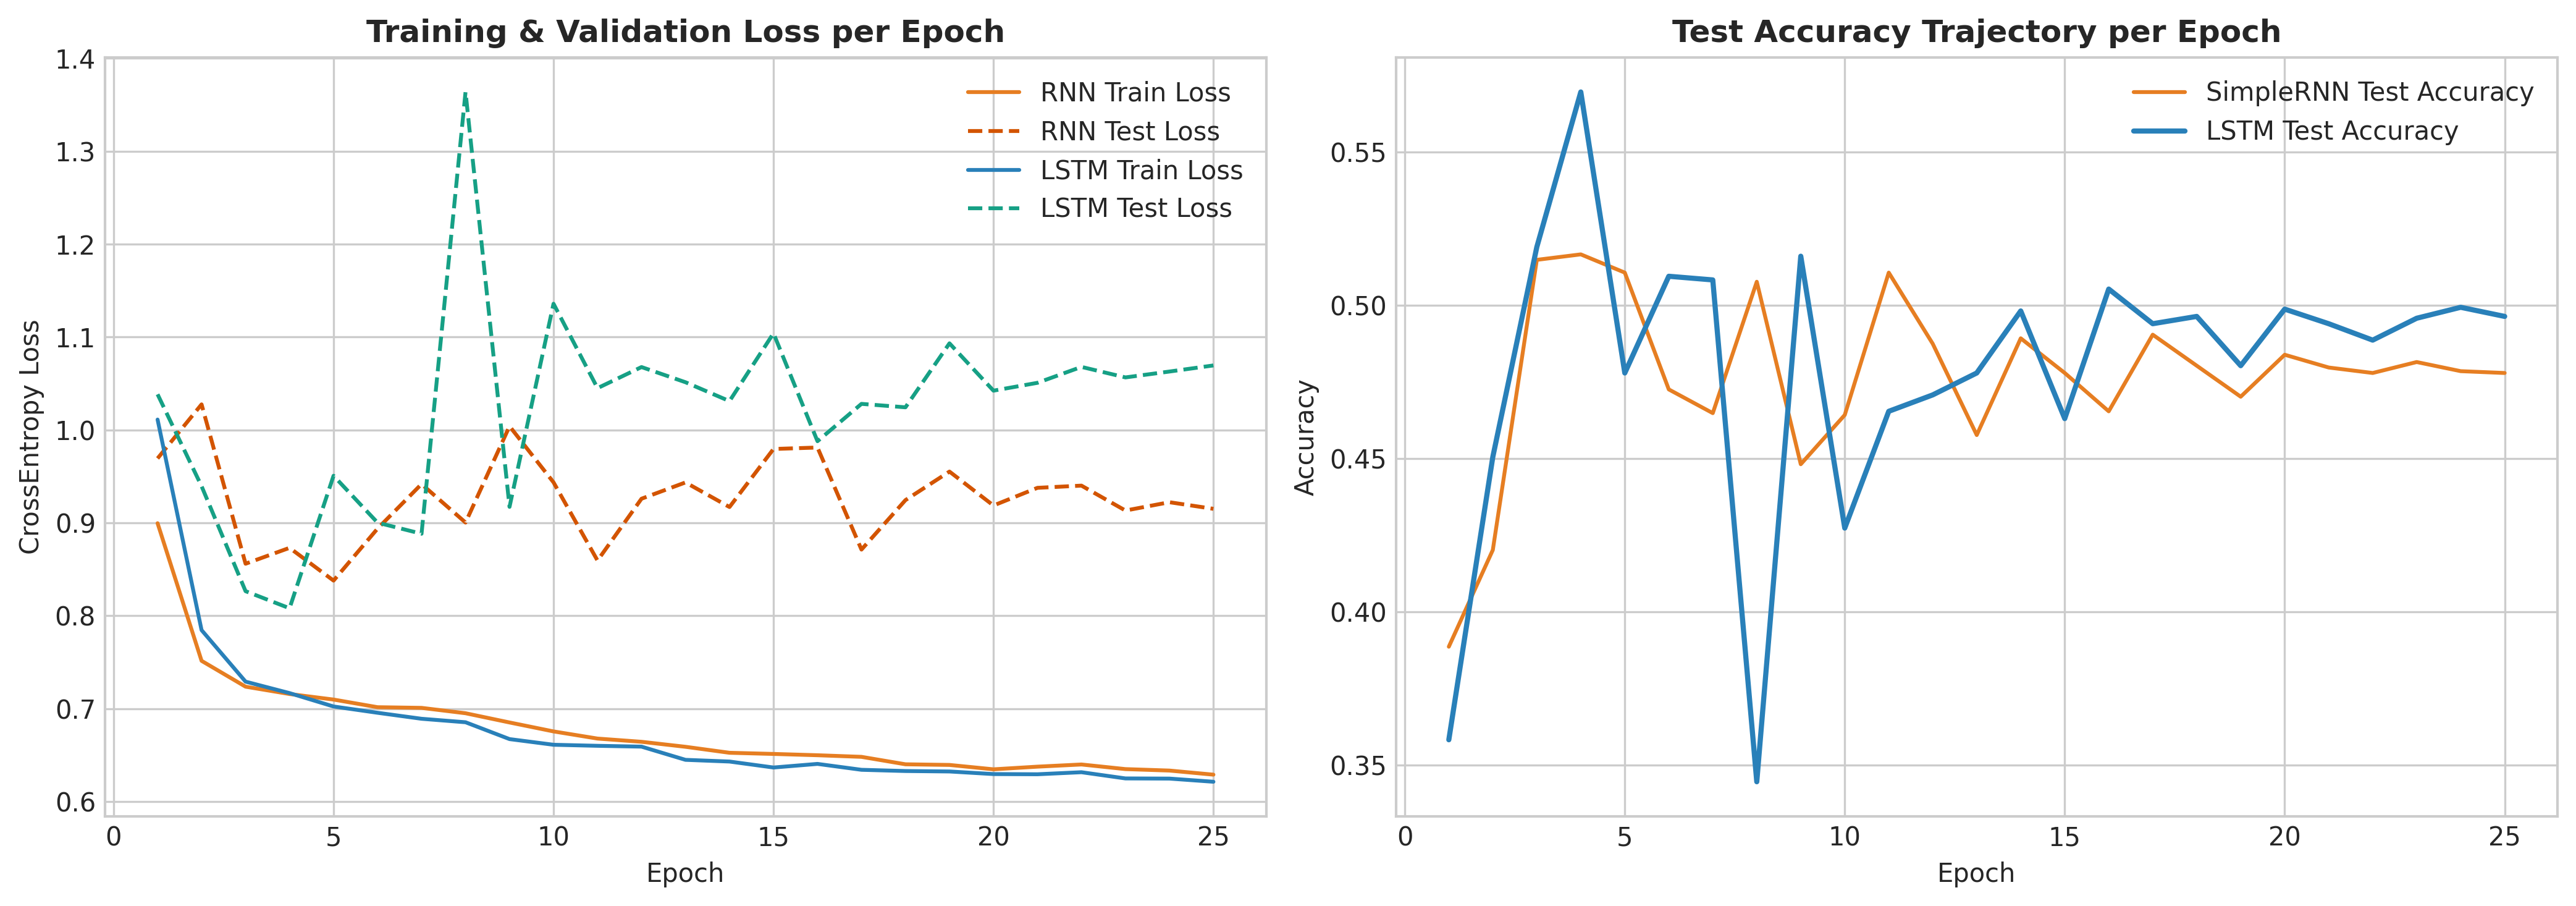


Confusion Matrices Across Models:


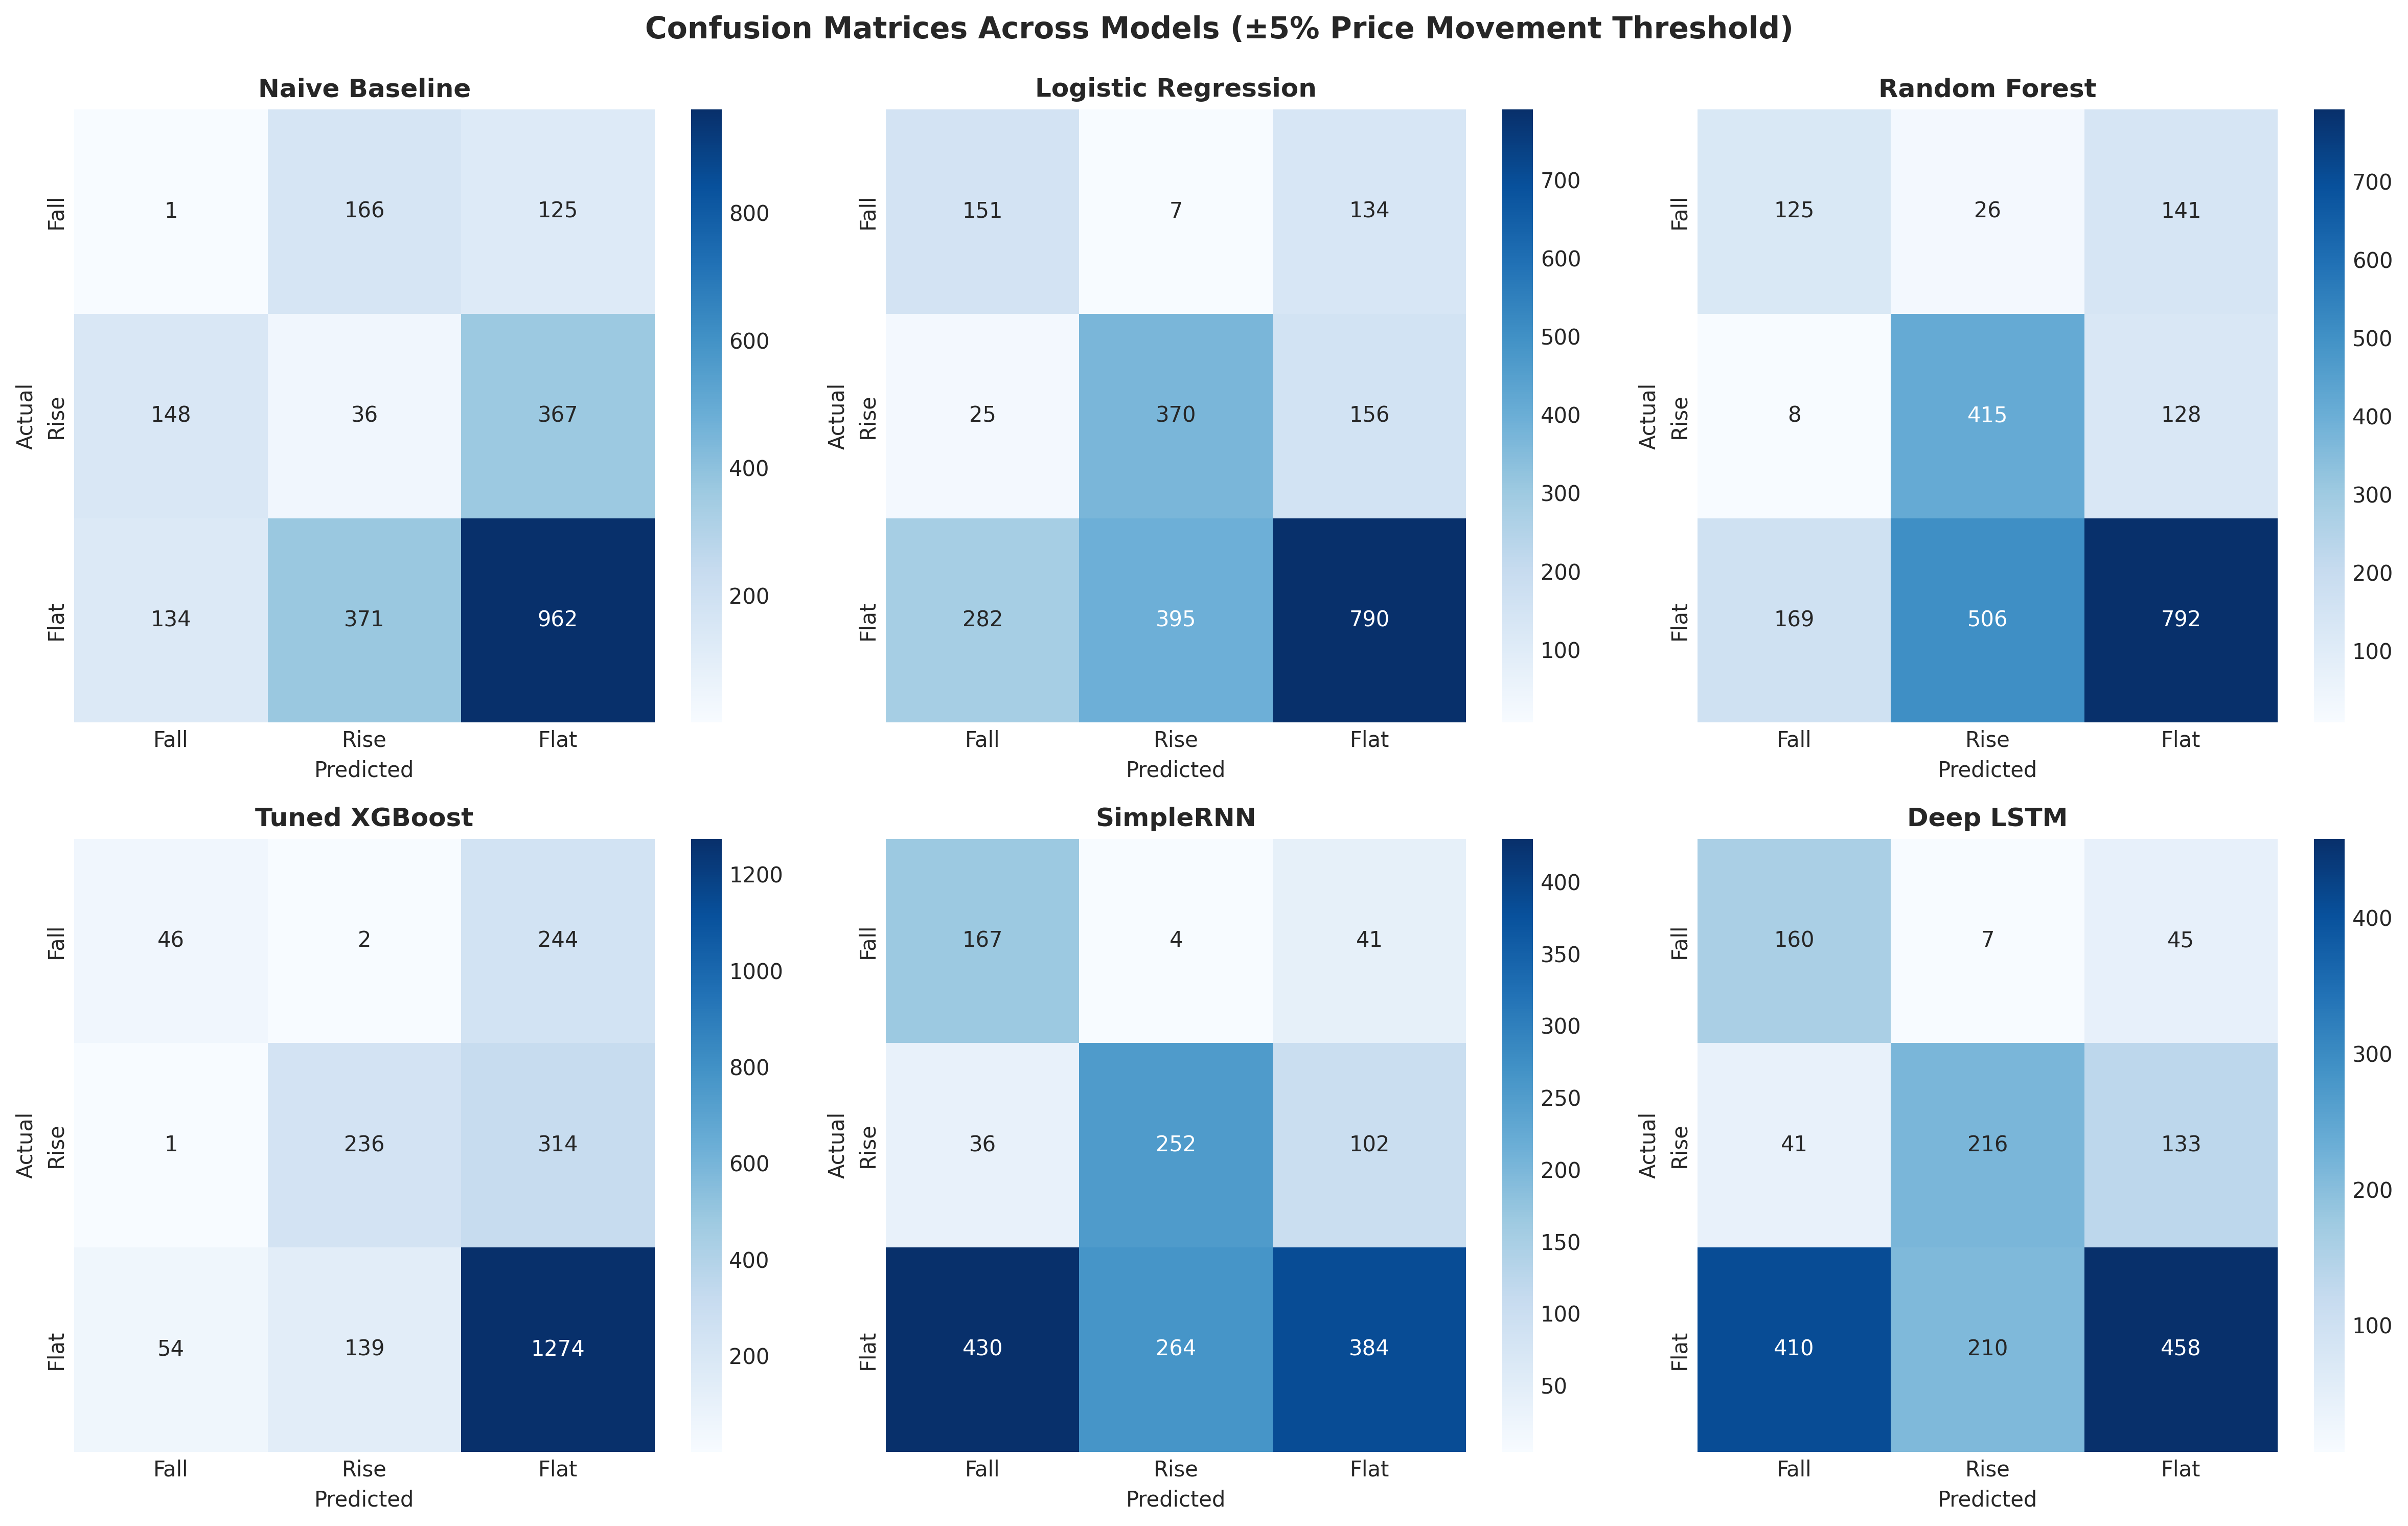


Metric Comparison Across Model Families:


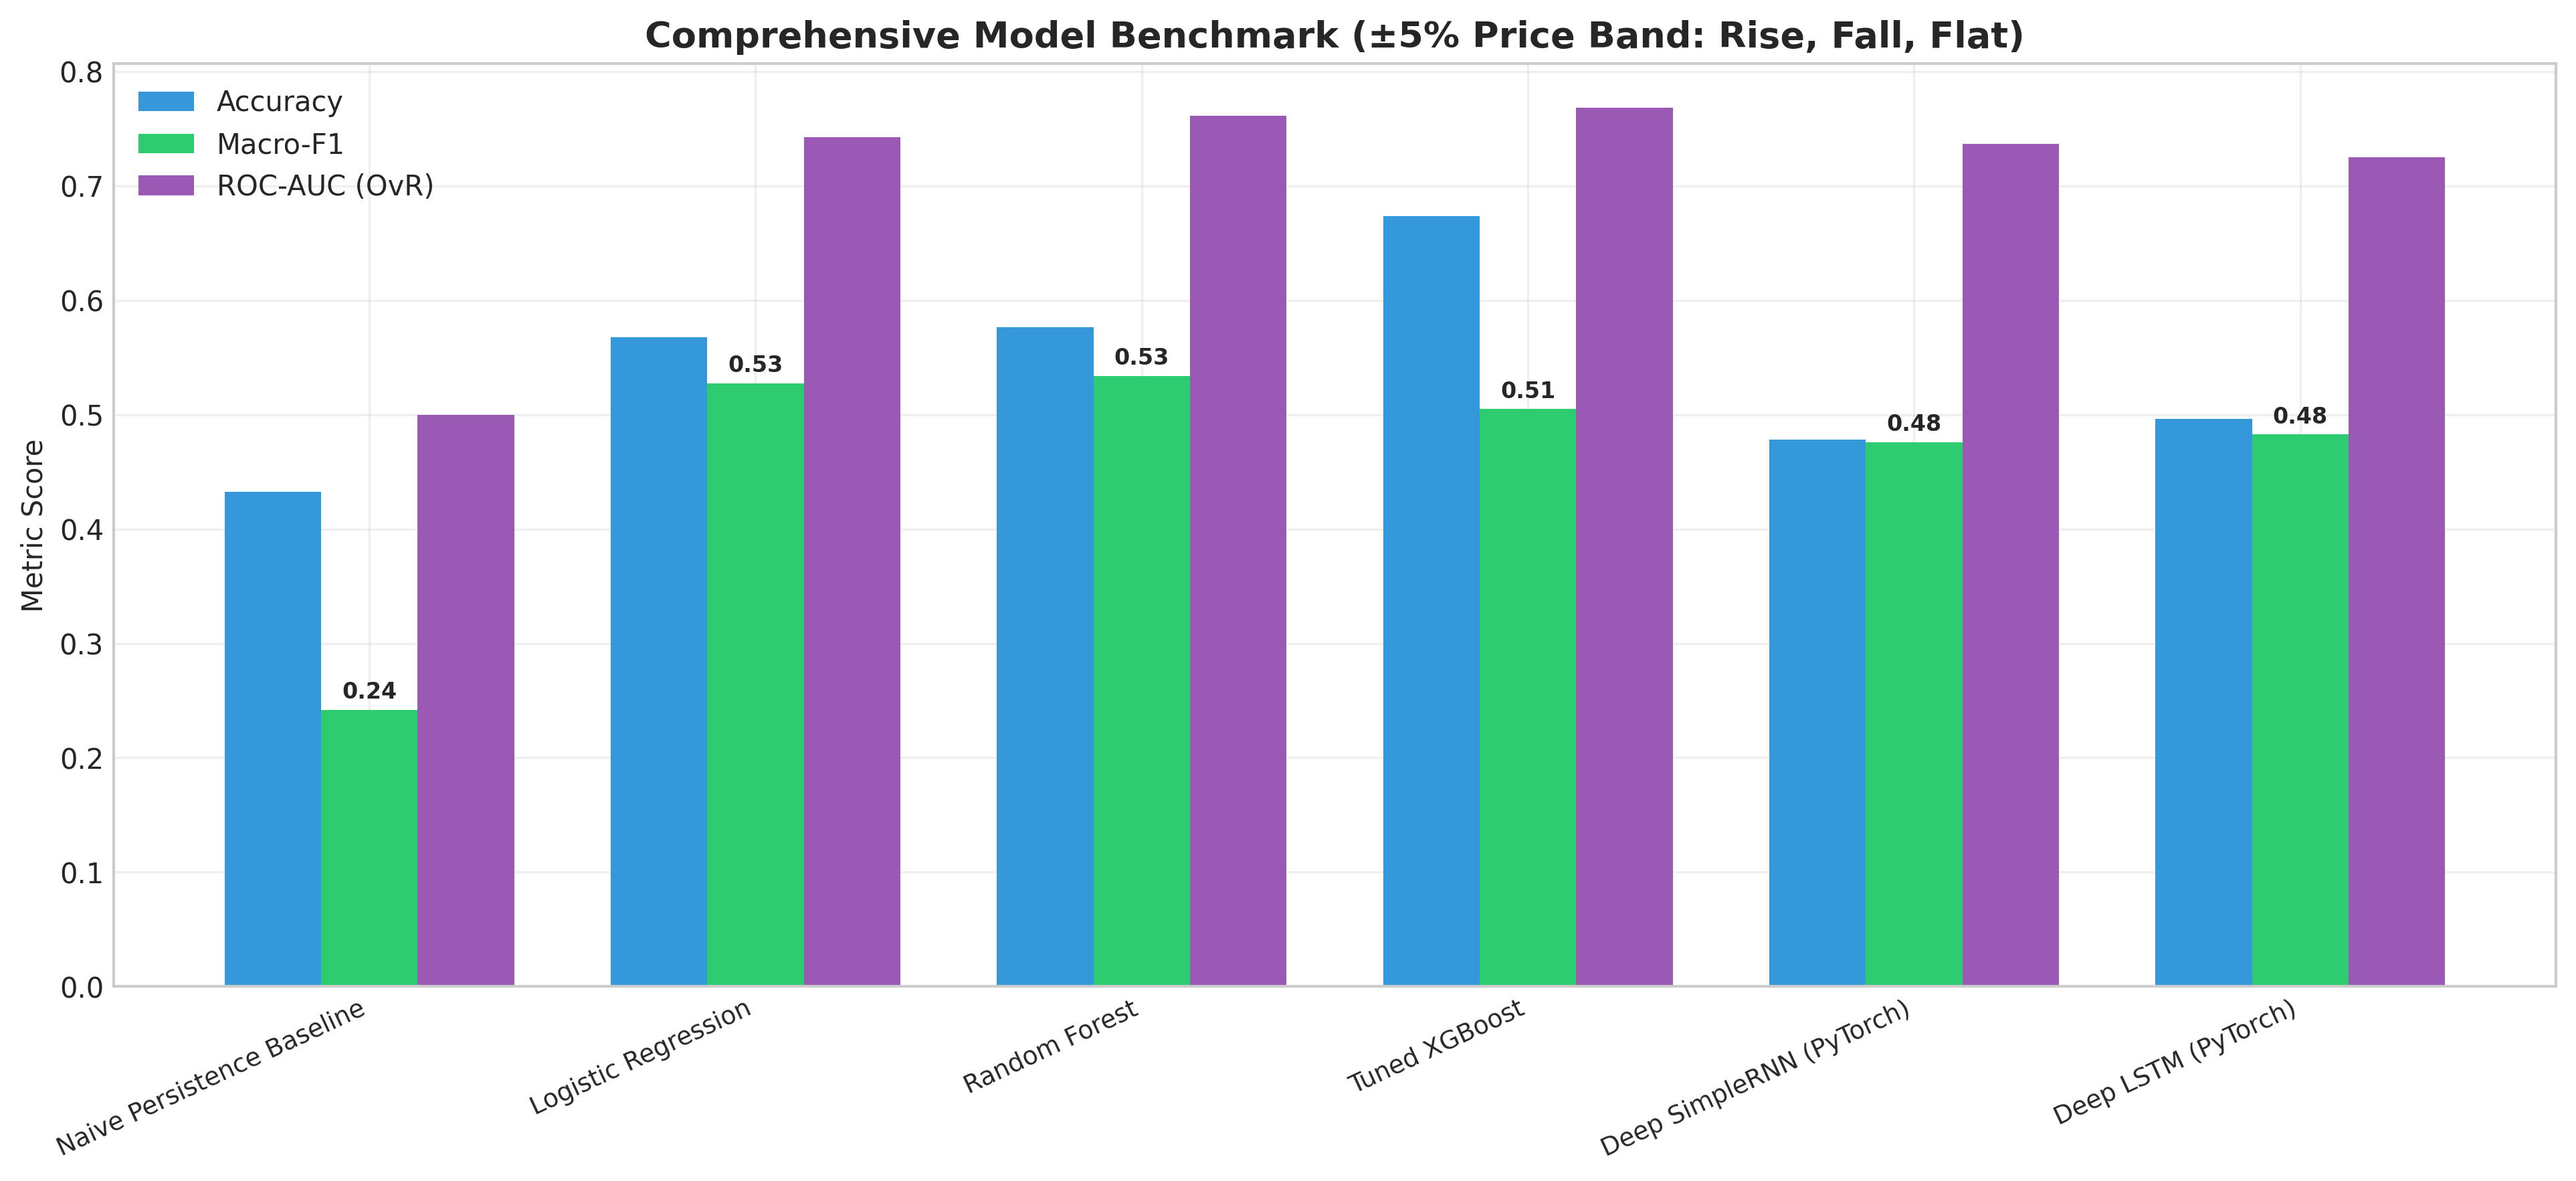

In [6]:
from IPython.display import Image, display

print("Loss Curves & Test Accuracy Trajectory:")
display(Image(filename="../reports/figures/deep_learning/chart1_lstm_rnn_loss_curves.png"))

print("\nConfusion Matrices Across Models:")
display(Image(filename="../reports/figures/deep_learning/chart2_confusion_matrices_all_models.png"))

print("\nMetric Comparison Across Model Families:")
display(Image(filename="../reports/figures/deep_learning/chart3_classification_metrics_comparison.png"))

## 6. Continuous Time-Series Price Regression (Deep LSTM Regressor)
In addition to classification, we evaluate an LSTM regressor trained to project continuous rupee prices.

,Model,RMSE,MAE,MAPE_Pct
0,Deep LSTM Regressor (PyTorch),127.19,98.47,4.69



LSTM Forecast vs Actual Price Series:


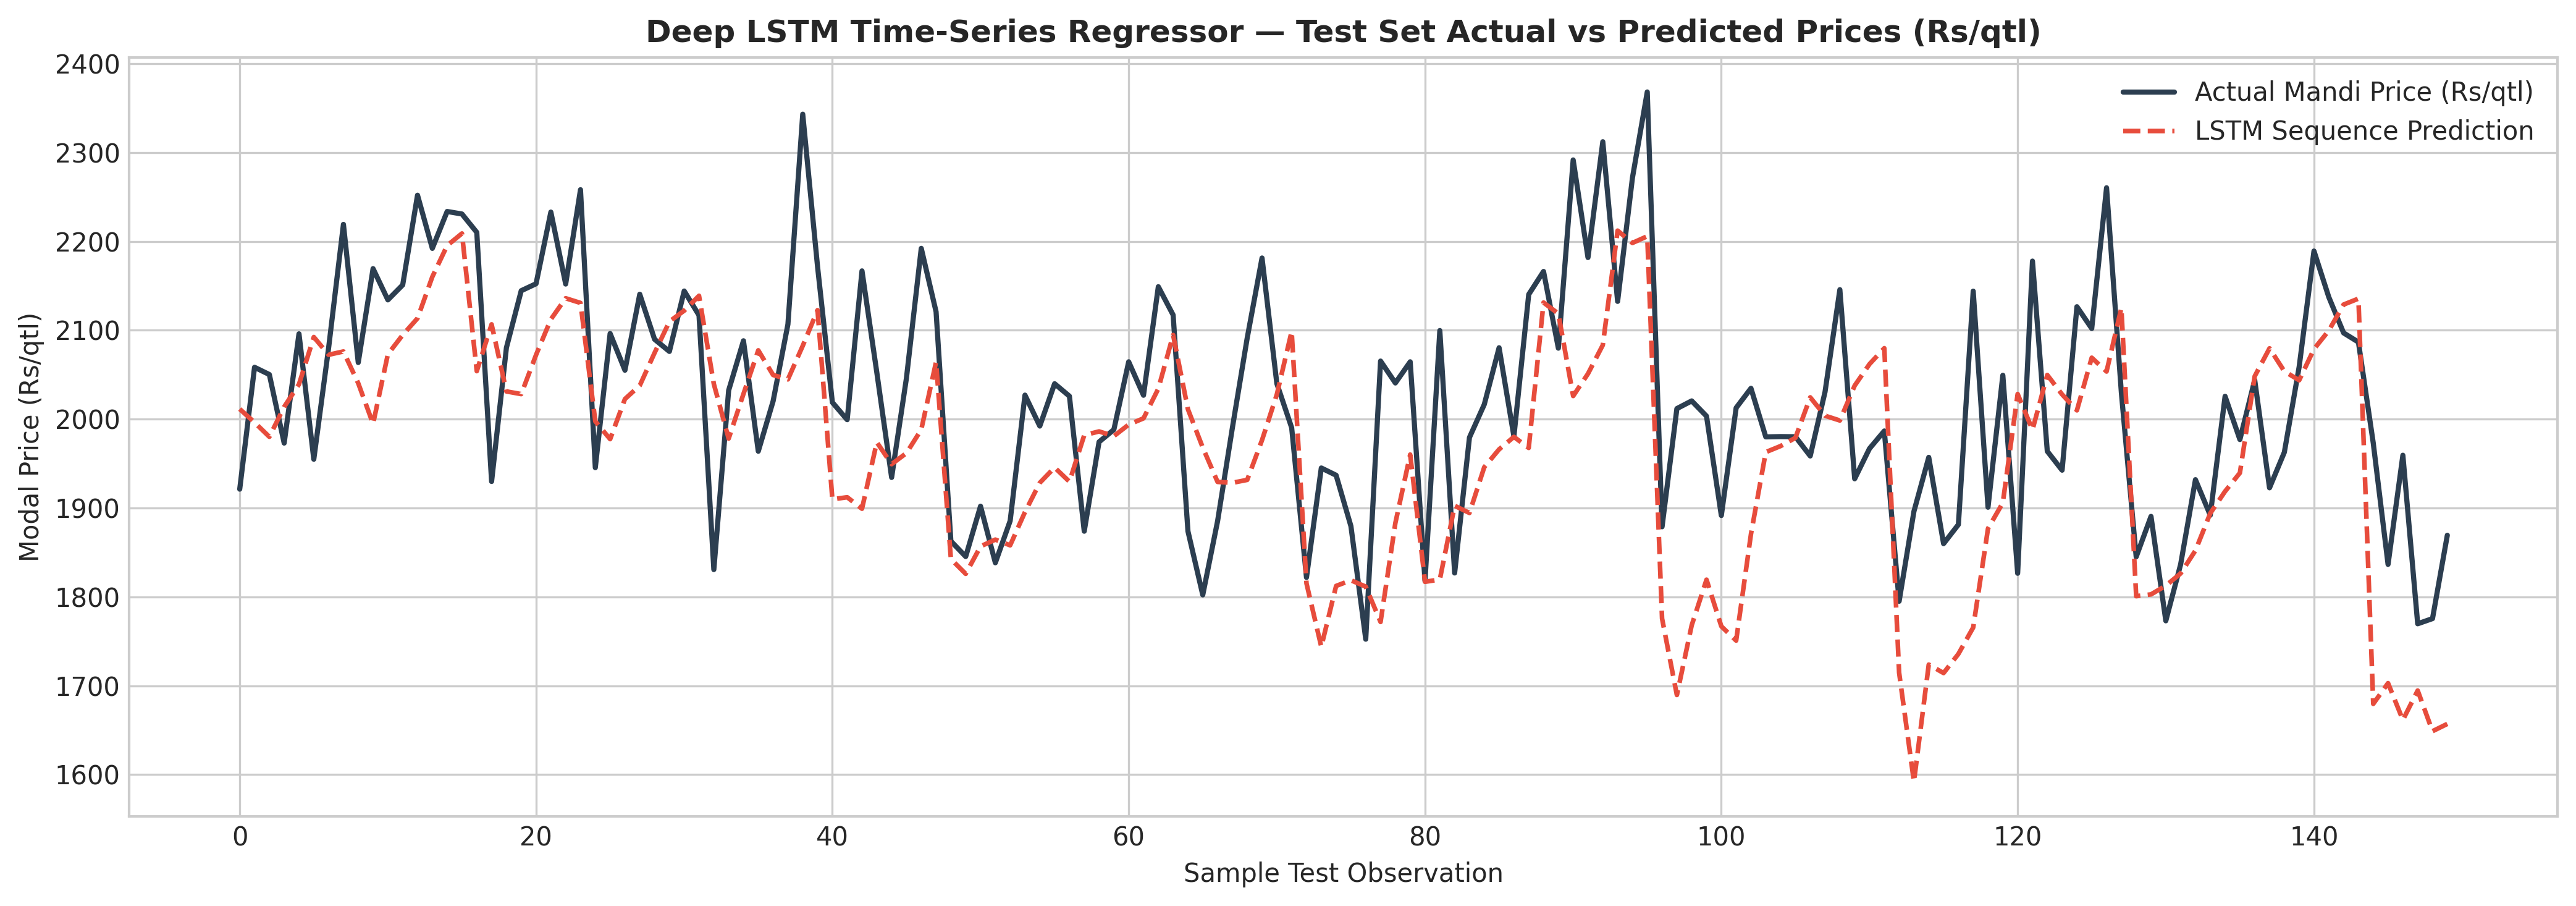

In [7]:
ts_path = "../reports/dl_timeseries_forecasting_metrics.csv"
ts_df = pd.read_csv(ts_path)
display(ts_df)

print("\nLSTM Forecast vs Actual Price Series:")
display(Image(filename="../reports/figures/deep_learning/chart4_lstm_forecast_vs_actual.png"))

## 7. Comparative Technical Synthesis
1. **XGBoost Dominates High-Precision Tabular Detection:**
   - **Tuned XGBoost** achieved **80.69% Binary Accuracy** and **ROC-AUC of 0.8121**, with **64.62% Precision** on price spikes.
   - On 3-class classification, XGBoost achieved **67.36% Accuracy**, correctly prioritizing the dominant 59% `Flat` majority class while filtering false alarms.
2. **Deep Sequence Models (LSTM & SimpleRNN) Excel at Spike Sensitivity (High Recall):**
   - **Deep SimpleRNN** attained **73.59% Recall** and **ROC-AUC of 0.8105** on binary price spikes.
   - **Deep LSTM** achieved **49.64% 3-Class Accuracy** and an out-of-sample continuous price forecasting MAPE of **4.69%** (RMSE: ₹127.19/qtl).
3. **Managerial Takeaway:**
   - For an **automated execution system** where minimizing false purchase orders is paramount, **Tuned XGBoost** is the superior deployment choice (64.6% precision).
   - For an **early-warning disaster monitor** where catching every single rain-induced spike is critical, **LSTM / SimpleRNN** provides superior risk recall (>73% sensitivity).